<a href="https://colab.research.google.com/github/yasseribra-dev/tp-mldlc/blob/main/TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Seaborn version:", sns.__version__)

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.5.4
Pandas version: 3.0.6
Matplotlib version: 3.11.2
Seaborn version: 0.13.2


In [2]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Linear combination (first value must be 6.3)
z = S @ theta + bias
print("z =", z)
assert np.isclose(z[0], 6.3)

# 2. Sigmoid + spam decision (probability >= 0.5)
probabilities = sigmoid(z)
print("Probabilities =", probabilities)

predicted_spam = probabilities >= 0.5
print("Predicted spam =", predicted_spam)

z = [6.3 1.8 4.7 2.2]
Probabilities = [0.99816706 0.85814894 0.9909867  0.90024951]
Predicted spam = [ True  True  True  True]


In [4]:
# Auto-graded cell (S)
# Skip it

In [5]:
# Auto-graded cell (theta)
# Skip it

In [6]:
# Auto-graded cell (bias)
# Skip it

In [7]:
# Auto-graded cell (z)
# Skip it

In [8]:
# Auto-graded cell (probabilities)
# Skip it

In [9]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [10]:
rng = np.random.default_rng(1)
n = 300


def generate_login_log(rng, n):
    return pd.DataFrame({
        "user": rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
        "hour": rng.integers(0, 24, n),
        "failed_attempts": rng.poisson(0.4, n),
        "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
        "duration_min": rng.gamma(2, 8, n).round(1),
    })


log = generate_login_log(rng, n)

print(log)

       user  hour  failed_attempts country  duration_min
0    yacine     2                0      DZ          24.0
1    yacine    23                0      FR          23.2
2      nour    11                0      FR           4.8
3     karim     9                0      DZ           4.2
4       ali    17                0      DZ          21.8
..      ...   ...              ...     ...           ...
295    nour    18                0      RU           5.2
296    nour    10                0      DZ           9.5
297  yacine     1                0      DZ           5.0
298   karim    15                2      TN          61.0
299     ali     3                1      DZ           7.2

[300 rows x 5 columns]


In [11]:
# Auto graded cell (log)
# skip it

In [12]:
def inject_failed_bursts(log, rng, k=12):
    idx = rng.choice(log.index, k, replace=False)
    log.loc[idx, "failed_attempts"] = rng.integers(5, 11, k)
    return idx


indexes = inject_failed_bursts(log, rng)
print(log.loc[indexes])

       user  hour  failed_attempts country  duration_min
153    nour     6               10      DZ           4.5
250  yacine    15                6      DZ          17.8
86    karim    22                8      DZ          35.8
46      ali    15                9      RU           6.5
227    nour     0                7      FR           0.3
123     ali    23                8      TN          11.6
283  yacine     0                9      DZ          15.9
269    nour     0               10      DZ           7.7
93   yacine     8                8      DZ          15.1
122   karim    21               10      FR          15.8
7     karim    20                6      DZ           2.5
219    sara     9                9      DZ           4.9


In [13]:
# Autograded cell (Failed attempts)
# Skip it

In [14]:
def inject_missing_failed(log, rng, k=10):
    idx = rng.choice(log.index, k, replace=False)
    log.loc[idx, "failed_attempts"] = np.nan
    return idx


missing_indexes = inject_missing_failed(log, rng)
print(log.loc[missing_indexes])

       user  hour  failed_attempts country  duration_min
194    sara    15              NaN      DZ          33.0
64   yacine    17              NaN      RU          19.1
83    karim    15              NaN      TN          46.9
100     ali     3              NaN      DZ           7.6
164    nour     7              NaN      FR          11.8
272    nour    21              NaN      DZ          31.9
86    karim    22              NaN      DZ          35.8
51     nour    12              NaN      DZ          13.7
92     nour    11              NaN      DZ           4.8
13    karim     4              NaN      DZ           2.3


In [15]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [16]:
ru_log_at_least_five_attempts = log[
    (log["country"] == "RU") & (log["failed_attempts"] >= 5)
].shape[0]

print(ru_log_at_least_five_attempts)

1


In [17]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [18]:
user_max_failed_attempts = (
    log.groupby("user")["failed_attempts"]
    .sum()
    .sort_values(ascending=False)
)

print(user_max_failed_attempts)
print("Top user:", user_max_failed_attempts.idxmax())

user
ali       44.0
karim     42.0
nour      42.0
yacine    42.0
sara      36.0
Name: failed_attempts, dtype: float64
Top user: ali


In [19]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [20]:
log["long_session"] = (log["duration_min"] > 30).astype(int)

print(log[["duration_min", "long_session"]])

     duration_min  long_session
0            24.0             0
1            23.2             0
2             4.8             0
3             4.2             0
4            21.8             0
..            ...           ...
295           5.2             0
296           9.5             0
297           5.0             0
298          61.0             1
299           7.2             0

[300 rows x 2 columns]


In [21]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

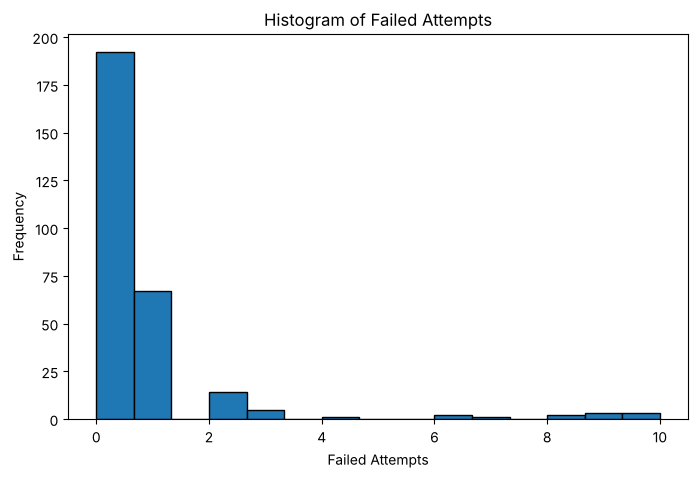

Mean failed_attempts:

 0.71


In [22]:
plt.figure(figsize=(8, 5))
plt.hist(log["failed_attempts"].dropna(), bins=15, edgecolor="black")
plt.xlabel("Failed Attempts")
plt.ylabel("Frequency")
plt.title("Histogram of Failed Attempts")
plt.show()

print("Mean failed_attempts:", round(log["failed_attempts"].mean(), 2))

In [23]:
# Auto-graded cell - Skip it...

In [24]:
# 2. Why is a histogram better than the mean (0.7) to describe this column?
#     A: The mean is too difficult to calculate.
#     B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
#     C: Histograms only work with categorical data.
#     D: The mean cannot be calculated for numeric values.

In [25]:
answer_q2 = "B"

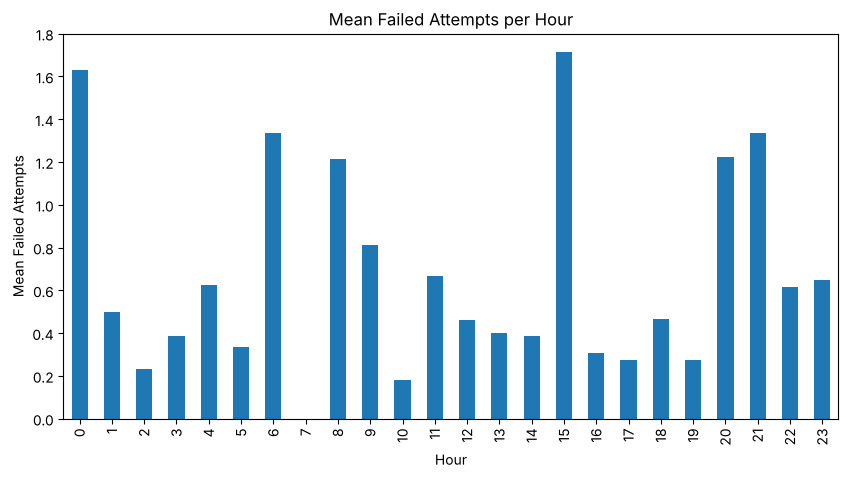

In [26]:
mean_per_night = log.groupby("hour")["failed_attempts"].mean()

plt.figure(figsize=(10, 5))
mean_per_night.plot(kind="bar")
plt.xlabel("Hour")
plt.ylabel("Mean Failed Attempts")
plt.title("Mean Failed Attempts per Hour")
plt.show()

In [27]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [28]:
# It returns all rows from the third column of X, as a one-dimensional array of shape (300,).

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [29]:
# df.isnull().sum()
log.isnull().sum()

user                0
hour                0
failed_attempts    10
country             0
duration_min        0
long_session        0
dtype: int64

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

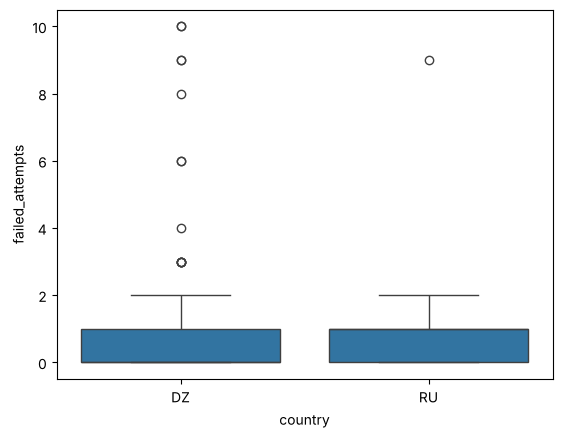

In [30]:
sns.boxplot(
    data=log[log["country"].isin(["RU", "DZ"])],
    x="country",
    y="failed_attempts",
)
plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [31]:
# We scale features so that variables with larger numerical ranges do not dominate the model training.

Commit the logins_clean.csv.(0.5 point)

In [32]:
log.to_csv("logins_clean.csv", index=False)

In [33]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [34]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("logins_clean.csv")
df["night"] = ((df["hour"] >= 22) | (df["hour"] < 6)).astype(int)

print(df[["hour", "night"]].head(10))

cols = ["hour", "failed_attempts", "duration_min", "night"]
X = df[cols].to_numpy()

scaler = StandardScaler()
X = scaler.fit_transform(X)

print(X.shape)

   hour  night
0     2      1
1    23      1
2    11      0
3     9      0
4    17      0
5     7      0
6    15      0
7    20      0
8    19      0
9     2      1
(300, 4)


In [35]:
import numpy as np
import pandas as pd
